In [91]:
import pandas as pd, numpy as np
import seaborn as sns, matplotlib.pyplot as plt
from sklearn.preprocessing import KBinsDiscretizer

pd.set_option('display.max_columns', 50)
df = pd.read_csv('spotify_artist_streaming_2020_2025.csv')
df.head()

,track_id,track_name,artist_name,album_name,release_date,genre,duration_ms,popularity,danceability,energy,key,loudness,mode,instrumentalness,tempo,stream_count,country,explicit,label,release_year,release_month,release_day_of_week,duration_minutes,popularity_category,loudness_category,key_name,mode_name,is_explicit_bool,release_quarter,is_weekend_release,log_stream_count,upbeat_score,artist_track_count
0,346d85e2-ffde-41b3-854a-589ed880b91f,Storm,Ethereal,The Hollow Journeys,2021-10-06,Pop,169594,47,0.6777,0.7949,9,-2.90,1,0.0065,111.89,46592,US,False,Self-Released,2021,10,Wednesday,2.83,Medium,Loud,A,Major,False,Q4,False,10.7492,0.6632,3232
1,12bc268a-363b-4f19-8fa8-0ced7ae1e462,Silent,The Wolfs,Ancient Thunder,2024-10-26,K-Pop,256755,26,0.9405,0.7163,1,-7.72,1,0.0198,129.17,5374,ES,False,Prism Audio,2024,10,Saturday,4.28,Medium,Moderate,C#,Major,False,Q4,True,8.5895,0.7615,20
2,30d627d9-878d-4bb3-be59-71feb6ed4f3f,Shattered Lines,LolaOre,Twisted Harbors,2022-11-12,Punk,170212,46,0.6853,0.9500,4,-2.38,1,0.0103,150.06,218262,US,False,Columbia Records,2022,11,Saturday,2.84,Medium,Loud,E,Major,False,Q4,True,12.2935,0.7828,199
3,85501bb9-d221-4339-9e2e-29b1b3daff0a,Breaking Roses,Clay Black,The Blinding Letters,2020-06-22,Pop,181250,4,0.7817,0.6943,6,-8.00,1,0.0151,121.16,5248,ZA,False,Midnight Records,2020,6,Monday,3.02,Low,Moderate,F#,Major,False,Q2,False,8.5658,0.6778,693
4,7bf92bd2-c6fe-4869-a90e-242bb8bbe7a3,Lines,Knot Hart,The Cosmic Letters,2024-01-22,Latin,160894,27,0.7200,0.4958,1,-6.38,1,0.0372,104.16,27420,US,False,Catalyst Records,2024,1,Monday,2.68,Medium,Moderate,C#,Major,False,Q1,False,10.2191,0.5494,12111


### Анализ параметов датасета: классы, доли классов, пропуск объектов

In [92]:
TARGET = 'popularity_category'   # change as needed

# Manual overrides (columns not found in your file are ignored automatically)
ID_COLS       = ['track_id']
DATETIME_COLS = ['release_date']
TEXT_COLS     = ['track_name', 'album_name']
# numeric-looking columns that are really categorical codes
CODED_CATEGORICAL = ['key', 'mode', 'explicit', 'release_month', 'release_day_of_week',
                     'release_quarter', 'release_quater', 'is_weekend_release', 'is_explicit_bool']
keep = lambda cols: [c for c in cols if c in df.columns]
ID_COLS, DATETIME_COLS, TEXT_COLS, CODED_CATEGORICAL = map(keep, [ID_COLS, DATETIME_COLS, TEXT_COLS, CODED_CATEGORICAL])

In [93]:
N, D = df.shape
print(f'N (instances) = {N:,}\nD (features)  = {D}')
df.dtypes

N (instances) = 50,000
D (features)  = 33


track_id                object
track_name              object
artist_name             object
album_name              object
release_date            object
genre                   object
duration_ms              int64
popularity               int64
danceability           float64
energy                 float64
key                      int64
loudness               float64
mode                     int64
instrumentalness       float64
tempo                  float64
stream_count             int64
country                 object
explicit                  bool
label                   object
release_year             int64
release_month            int64
release_day_of_week     object
duration_minutes       float64
popularity_category     object
loudness_category       object
key_name                object
mode_name               object
is_explicit_bool          bool
release_quarter         object
is_weekend_release        bool
log_stream_count       float64
upbeat_score           float64
artist_t

In [94]:
missing_pct_total = df.isna().sum().sum() / df.size * 100
print(f'Missing values overall: {missing_pct_total:.3f}% of all cells')
miss = (df.isna().mean()*100).sort_values(ascending=False)
miss[miss>0].to_frame('missing_%')

Missing values overall: 0.000% of all cells


,missing_%


In [95]:
def feature_type(col):
    s = df[col]
    if col in ID_COLS: return 'identifier'
    if col in DATETIME_COLS: return 'datetime'
    if col in TEXT_COLS: return 'text'
    if col in CODED_CATEGORICAL or s.dtype == bool or s.nunique(dropna=True) <= 2: return 'categorical'
    if pd.api.types.is_numeric_dtype(s): return 'numerical'
    # remaining strings: mostly-unique -> text, otherwise categorical
    if s.nunique() / max(len(s),1) > 0.5: return 'text'
    return 'categorical'

types = pd.Series({c: feature_type(c) for c in df.columns})
type_table = pd.DataFrame({'type': types, 'dtype': df.dtypes.astype(str), 'n_unique': df.nunique()})
display(type_table.sort_values('type'))
type_counts = types.value_counts()
type_counts

,type,dtype,n_unique
country,categorical,object,30
release_month,categorical,int64,12
release_day_of_week,categorical,object,7
mode,categorical,int64,2
popularity_category,categorical,object,4
key,categorical,int64,12
loudness_category,categorical,object,3
label,categorical,object,30
key_name,categorical,object,12
is_explicit_bool,categorical,bool,2


categorical    16
numerical      13
text            2
identifier      1
datetime        1
Name: count, dtype: int64

In [96]:
num_cols = types[types=='numerical'].index.tolist()
out_mask = pd.DataFrame(False, index=df.index, columns=num_cols)
rows = []
for c in num_cols:
    q1, q3 = df[c].quantile([.25,.75]); iqr = q3-q1
    m = (df[c] < q1-1.5*iqr) | (df[c] > q3+1.5*iqr)
    out_mask[c] = m
    rows.append((c, int(m.sum()), m.mean()*100))
out_table = pd.DataFrame(rows, columns=['feature','n_outliers','%']).sort_values('n_outliers', ascending=False)
n_outlier_cells = int(out_mask.values.sum()); n_outlier_rows = int(out_mask.any(axis=1).sum())
print(f'Outlier cells: {n_outlier_cells:,} | rows with >=1 outlier: {n_outlier_rows:,} ({n_outlier_rows/N*100:.2f}%)')
out_table

Outlier cells: 15,891 | rows with >=1 outlier: 12,569 (25.14%)


,feature,n_outliers,%
7,stream_count,6909,13.818
5,instrumentalness,4755,9.510
11,upbeat_score,1157,2.314
6,tempo,746,1.492
2,danceability,673,1.346
3,energy,385,0.770
4,loudness,325,0.650
1,popularity,303,0.606
10,log_stream_count,289,0.578
0,duration_ms,177,0.354


,count,%
popularity_category,,
Very High,247,0.49
High,5181,10.36
Medium,21304,42.61
Low,23268,46.54


K = 4
Class imbalance (smallest -> largest): 0.5/10.4/42.6/46.5
Imbalance ratio (majority/minority): 94.2:1


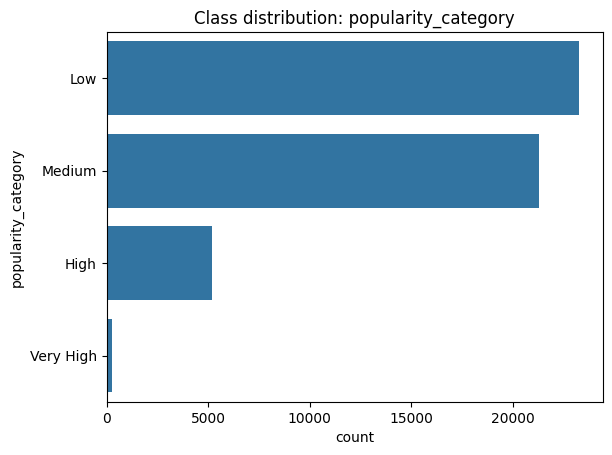

In [97]:
y = df[TARGET].dropna()
counts = y.value_counts().sort_values()          # ascending: smallest -> largest class
pct = counts / counts.sum() * 100

K = len(counts)
imbalance_str = '/'.join(f'{p:.1f}' for p in pct)

display(pd.DataFrame({'count': counts, '%': pct.round(2)}))
print(f'K = {K}')
print(f'Class imbalance (smallest -> largest): {imbalance_str}')
print(f'Imbalance ratio (majority/minority): {counts.max() / counts.min():.1f}:1')

sns.countplot(y=y, order=counts.index[::-1])
plt.title(f'Class distribution: {TARGET}'); plt.show()

In [98]:
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

MISSING_COLS = ['tempo', 'loudness', 'danceability', 'energy', 'instrumentalness',
                'duration_ms', 'stream_count',      # numerical
                'genre', 'country', 'label']        # categorical
MISSING_COLS = [c for c in MISSING_COLS if c in df.columns]

df_miss = df.copy()
for c in MISSING_COLS:
    rate = rng.uniform(0.02, 0.10)                  # 2-10% missing per column (MCAR)
    mask = rng.random(len(df_miss)) < rate
    df_miss[c] = df_miss[c].mask(mask)

assert df_miss[TARGET].isna().sum() == 0            # target is never touched

report = (df_miss[MISSING_COLS].isna().mean() * 100).round(2).sort_values(ascending=False)
print(f'Total missing: {df_miss.isna().sum().sum() / df_miss.size * 100:.2f}% of all cells')
report.to_frame('missing_%')

Total missing: 2.13% of all cells


,missing_%
duration_ms,9.49
country,8.31
tempo,8.14
instrumentalness,8.06
stream_count,7.81
label,6.88
energy,6.72
danceability,6.09
loudness,5.43
genre,3.44


In [99]:
from sklearn.model_selection import train_test_split

# Leakage: popularity_category is a binned version of popularity
LEAKAGE = ['popularity']

# Duplicated information (a raw column and its derived copy)
DUPLICATES = [
    'duration_minutes',                       # = duration_ms / 60000
    'log_stream_count',                       # = log(stream_count)
    'key_name', 'mode_name',                  # labels of key / mode
    'is_explicit_bool',                       # = explicit
    'loudness_category',                      # binned loudness
    'release_date', 'release_quater', 'release_quarter',   # parts kept: year, month, day_of_week
    'is_weekend_release',                     # = from release_day_of_week
]
IDENTIFIERS = ['track_id']                    # unique per row, no signal

drop_cols = LEAKAGE + DUPLICATES + IDENTIFIERS + [TARGET]
X = df_miss.drop(columns=drop_cols, errors='ignore')
y = df_miss[TARGET]
y_num = df_miss['popularity']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

X_train_num, X_test_num, y_train_num, y_test_num = train_test_split(
    X, y_num, test_size=0.2, random_state=RANDOM_STATE
)

print(f'Dropped: {[c for c in drop_cols if c in df_miss.columns]}')
print(f'X_train: {X_train.shape} | X_test: {X_test.shape}')
display(pd.DataFrame({
    'train_%': (y_train.value_counts(normalize=True) * 100).round(2),
    'test_%':  (y_test.value_counts(normalize=True) * 100).round(2),
}))

Dropped: ['popularity', 'duration_minutes', 'log_stream_count', 'key_name', 'mode_name', 'is_explicit_bool', 'loudness_category', 'release_date', 'release_quarter', 'is_weekend_release', 'track_id', 'popularity_category']
X_train: (40000, 21) | X_test: (10000, 21)


,train_%,test_%
popularity_category,,
Low,46.54,46.54
Medium,42.61,42.61
High,10.36,10.36
Very High,0.50,0.49


### Разведывательный анализ данных

0. Описать задачу словами: предсказать популярность трека (численно или по классу популярности) на платформе spotify основе его параметров
1. Прочитать данные - уже сделано
2. Разибить на обучающую и тестовую выборки - уже сделано
3. Визуализировать данные (среднее, разброс, корреляционная матрица)

Зависимость от темпа:

In [115]:

tempo = X_train_num['tempo']
duration_ms = X_train_num['duration_ms']
key = X_train_num['key']
plt.scatter(x=tempo, y=y_train_num, s=5, alpha=0.3)   
plt.xlabel('tempo'); plt.ylabel('popularity')

print(tempo.mean())
print(tempo.std())
print(tempo.corr(y_train_num))   

KeyError: 'key'

Зависимость от длительности:

209850.96541149818
44513.7122420631
0.010175969877634021


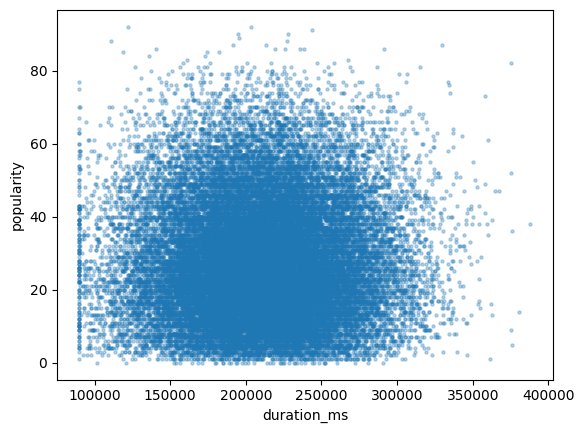

In [ ]:
plt.scatter(x=duration_ms, y=y_train_num, s=5, alpha=0.3)
plt.xlabel('duration_ms'); plt.ylabel('popularity')
print(duration_ms.mean())
print(duration_ms.std())
print(duration_ms.corr(y_train_num))

Зависимость от тональности:

5.468125
3.4503741262963477
0.006895734319475472


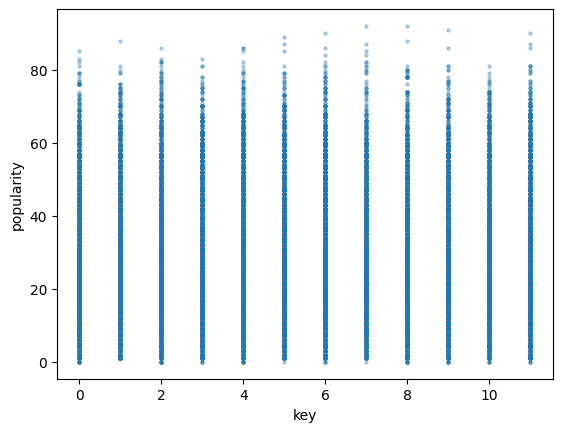

In [ ]:
plt.scatter(x=key, y=y_train_num, s=5, alpha=0.3)
plt.xlabel('key'); plt.ylabel('popularity')
print(key.mean())
print(key.std())
print(key.corr(y_train_num))

Зависимость от danceability:

0.6617332517687111
0.1638251362096379
0.0005625576040018898


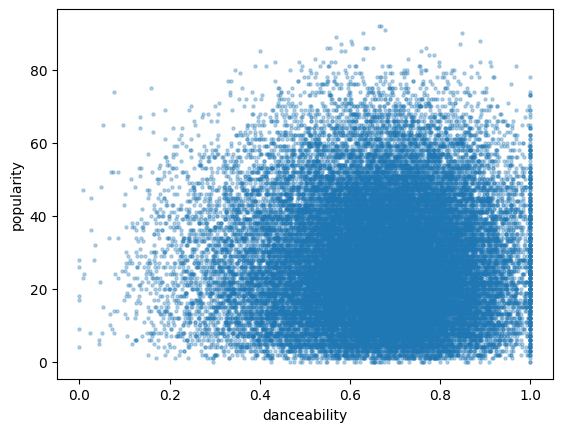

In [ ]:

danceability = X_train_num['danceability']
plt.scatter(x=danceability, y=y_train_num, s=5, alpha=0.3)
plt.xlabel('danceability'); plt.ylabel('popularity')
print(danceability.mean())
print(danceability.std())
print(danceability.corr(y_train_num))

Везде очень маленькая корреляция, но самая большая - с тональностью.

4. Выбросы есть, но их немного. Рассмотрим ящик с усами для популярности:

<Axes: xlabel='loudness_category', ylabel='popularity'>

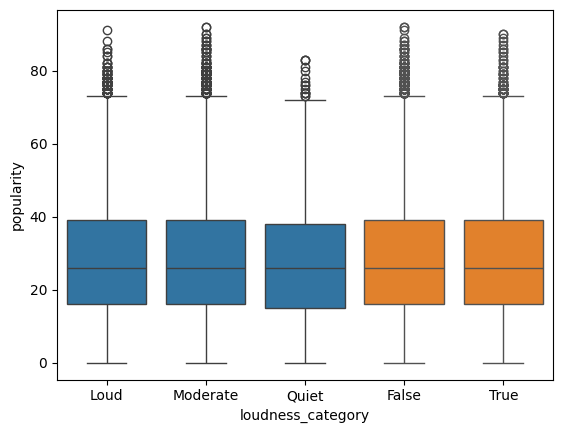

In [ ]:
sns.boxplot(x="loudness_category", y="popularity", data=df)
sns.boxplot(x="explicit", y="popularity", data=df)

наша цель - добиться определения самых популярных треков в том числе. Выбросов не много, а те, что есть - как раз самые популярные треки (см. 7 ячейку в этом документе)


<Axes: xlabel='key', ylabel='popularity'>

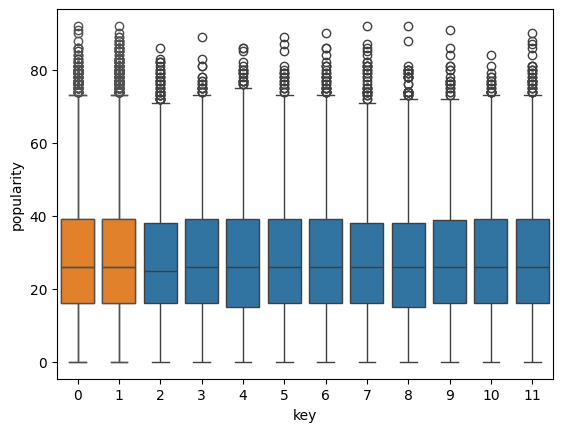

In [ ]:
sns.boxplot(x="key", y="popularity", data=df)
sns.boxplot(x="mode", y="popularity", data=df)

<Axes: xlabel='popularity_category', ylabel='popularity'>

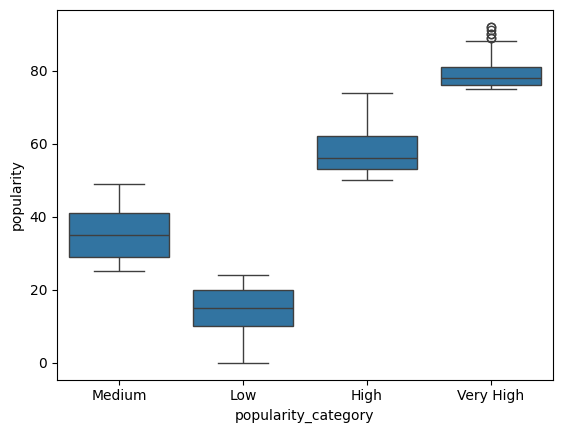

In [ ]:
sns.boxplot(x="popularity_category", y='popularity', data=df)

5. Пропущенные значения были сгенерированы и положены в df_miss (см. 9 ячейку). Предлагается заменить пропущенные значения на моду.

In [ ]:

def fill_with_mode(train, test):
    modes = train.mode(dropna=True).iloc[0]
    return train.fillna(modes), test.fillna(modes)

X_train, X_test = fill_with_mode(X_train, X_test)
X_train_num, X_test_num = fill_with_mode(X_train_num, X_test_num)

print('Пропусков осталось:', X_train.isna().sum().sum(), X_test.isna().sum().sum(),
      X_train_num.isna().sum().sum(), X_test_num.isna().sum().sum())

Пропусков осталось: 0 0 0 0


6. Обработка категориальных признаков. Рассмотрим оставшиеся признаки:

In [ ]:
X_train.dtypes

track_name              object
artist_name             object
album_name              object
genre                   object
duration_ms            float64
danceability           float64
energy                 float64
key                      int64
loudness               float64
mode                     int64
instrumentalness       float64
tempo                  float64
stream_count           float64
country                 object
explicit                  bool
label                   object
release_year             int64
release_month            int64
release_day_of_week     object
upbeat_score           float64
artist_track_count       int64
dtype: object

Из них категориальные: artist_name (500), genre (20), key (12), mode (2), country (30), explicit (2), label (30), release_month (12), release_day_of_week (7).
2 признака тестовые (имя трека и имя альбома). Их предлагается выбросить. Остальные заменить на числа.

In [ ]:
X_train = X_train.drop(columns=['track_name', 'album_name'])
X_train_num = X_train_num.drop(columns=['track_name', 'album_name'])
X_test = X_test.drop(columns=['track_name', 'album_name'])
X_test_num = X_test_num.drop(columns=['track_name', 'album_name'])

# --- Категории -> числа ---
FREQ_COLS = ['artist_name']                                          # 500 значений: one-hot раздул бы таблицу
OHE_COLS  = ['genre', 'country', 'label', 'release_day_of_week', 'key']   # номинальные, значений немного
# explicit -> 0/1; mode (0/1), release_month, release_year и так числа

def fit_freq(X_fit):
    """Доля каждого исполнителя в ОБУЧАЮЩЕЙ выборке."""
    return {c: X_fit[c].value_counts(normalize=True) for c in FREQ_COLS}

def encode(X, freq):
    X = X.copy()
    X['explicit'] = X['explicit'].astype(int)
    for c in FREQ_COLS:
        X[c] = X[c].map(freq[c]).fillna(0.0)          # неизвестный исполнитель -> 0
    return pd.get_dummies(X, columns=OHE_COLS, dtype=int)

freq_cls = fit_freq(X_train)
X_train = encode(X_train, freq_cls)
X_test  = encode(X_test, freq_cls).reindex(columns=X_train.columns, fill_value=0)

freq_reg = fit_freq(X_train_num)
X_train_num = encode(X_train_num, freq_reg)
X_test_num  = encode(X_test_num, freq_reg).reindex(columns=X_train_num.columns, fill_value=0)

print(X_train.shape, X_test.shape, X_train_num.shape, X_test_num.shape)
print(X_train.dtypes.value_counts())

(40000, 113) (10000, 113) (40000, 113) (10000, 113)
int64      104
float64      9
Name: count, dtype: int64


7. **Нужна ли нормализация? Да.** Признаки в совершенно разных масштабах: `duration_ms` ~ 10^5, `stream_count` до миллионов, `danceability`/`energy` в диапазоне 0–1. 
- Метод k ближайших соседей считает евклидово расстояние, поэтому признак с большим масштабом полностью «перетянет» остальные. 
- Для линейной регрессии масштаб не меняет качество, но делает коэффициенты сравнимыми.

Что делаем: `stream_count` сильно скошен (по IQR у него ~14% выбросов), поэтому сначала берём `log1p`, затем `StandardScaler` (среднее 0, std 1) для непрерывных признаков. 

In [ ]:
from sklearn.preprocessing import StandardScaler

SCALE_COLS = ['duration_ms', 'danceability', 'energy', 'loudness', 'instrumentalness', 'tempo',
              'stream_count', 'release_year', 'release_month', 'upbeat_score', 'artist_track_count', 'artist_name']
SCALE_COLS = [c for c in SCALE_COLS if c in X_train.columns]

def scale(Xtr, Xte):
    Xtr, Xte = Xtr.copy(), Xte.copy()
    for d in (Xtr, Xte):
        d['stream_count'] = np.log1p(d['stream_count'])
    sc = StandardScaler().fit(Xtr[SCALE_COLS])
    Xtr[SCALE_COLS] = sc.transform(Xtr[SCALE_COLS])
    Xte[SCALE_COLS] = sc.transform(Xte[SCALE_COLS])
    return Xtr, Xte

Xs_train, Xs_test = scale(X_train, X_test)                    # для классификации
Xs_train_num, Xs_test_num = scale(X_train_num, X_test_num)    # для регрессии

Xs_train[SCALE_COLS].describe().loc[['mean', 'std']].round(2)

,duration_ms,danceability,energy,loudness,instrumentalness,tempo,stream_count,release_year,release_month,upbeat_score,artist_track_count,artist_name
mean,-0.0,-0.0,0.0,0.0,0.0,0.0,0.0,-0.0,0.0,-0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


8. Запустить регрессию для популярности и метод k-ближайших соседей (или другой, более подходящий алгоритм) для категории популярности. 

**Регрессия** (целевая переменная – `popularity`, 0–100): линейная регрессия. В качестве ориентира – «глупая» модель, всегда предсказывающая среднее обучающей выборки.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

reg = LinearRegression().fit(Xs_train_num, y_train_num)
base_reg = DummyRegressor(strategy='mean').fit(Xs_train_num, y_train_num)

def reg_metrics(model, Xtr, ytr, Xte, yte):
    out = {}
    for name, X, y in (('train', Xtr, ytr), ('test', Xte, yte)):
        p = model.predict(X)
        out[name] = {'RMSE': np.sqrt(mean_squared_error(y, p)), 'MAE': mean_absolute_error(y, p), 'R2': r2_score(y, p)}
    return pd.DataFrame(out).T

reg_table = pd.concat({'LinearRegression': reg_metrics(reg, Xs_train_num, y_train_num, Xs_test_num, y_test_num),
                       'Baseline (среднее)': reg_metrics(base_reg, Xs_train_num, y_train_num, Xs_test_num, y_test_num)})
display(reg_table.round(3))

coef = pd.Series(reg.coef_, index=Xs_train_num.columns).sort_values(key=np.abs, ascending=False)
display(coef.head(10).round(3).to_frame('coef (на стандартизованных признаках)'))

RMSE     MAE     R2
LinearRegression   train   8.529   6.362  0.715
                   test    8.509   6.386  0.720
Baseline (среднее) train  15.980  13.032  0.000
                   test   16.075  13.130 -0.000

,coef (на стандартизованных признаках)
stream_count,13.248
artist_track_count,-12.666
artist_name,12.647
label_Epic Records,2.060
label_RCA Records,2.006
label_Def Jam Recordings,1.605
label_Sony Music Entertainment,1.565
label_Universal Music Group,1.497
label_Atlantic Records,1.446
label_Warner Music Group,1.427


**Классификация** (целевая – `popularity_category`, 4 класса): метод k ближайших соседей. Классы сильно несбалансированы (≈0.5 / 10 / 43 / 47 %). Ориентир – модель, всегда предсказывающая самый частый класс.

Оптимальное k по CV (balanced accuracy): 7


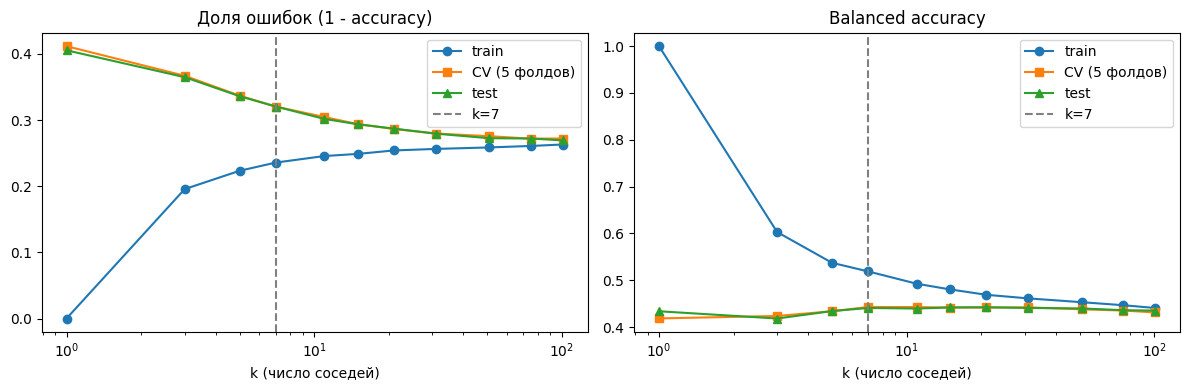

train                      CV                    test                 
     error bal_acc macro_f1  error bal_acc macro_f1  error bal_acc macro_f1
k                                                                          
1    0.000   1.000    1.000  0.412   0.418    0.430  0.406   0.434    0.448
3    0.196   0.603    0.656  0.367   0.424    0.445  0.365   0.418    0.437
5    0.223   0.537    0.574  0.337   0.434    0.456  0.336   0.434    0.456
7    0.236   0.519    0.552  0.320   0.443    0.466  0.320   0.441    0.463
11   0.246   0.492    0.519  0.305   0.443    0.462  0.302   0.439    0.456
15   0.249   0.480    0.501  0.294   0.442    0.458  0.294   0.442    0.457
21   0.254   0.469    0.487  0.287   0.442    0.456  0.287   0.442    0.457
31   0.256   0.461    0.477  0.280   0.442    0.455  0.279   0.441    0.453
51   0.259   0.453    0.465  0.276   0.438    0.447  0.273   0.440    0.449
75   0.261   0.447    0.456  0.272   0.435    0.441  0.272   0.436    0.443
101  0.263   0.441    0.447  0.272   0.431    0.434  0.269   0.435    0.440

In [ ]:
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix, classification_report

CLASSES = ['Low', 'Medium', 'High', 'Very High']          # порядок по убыванию частоты (при ничьей в голосовании победит частый класс)
cls2i = {c: i for i, c in enumerate(CLASSES)}
ytr = y_train.map(cls2i).to_numpy(); yte = y_test.map(cls2i).to_numpy()
KS = [1, 3, 5, 7, 11, 15, 21, 31, 51, 75, 101]

def vote(nbr_labels, k):
    """Предсказание kNN по меткам k ближайших соседей (равные веса)."""
    counts = (nbr_labels[:, :k, None] == np.arange(len(CLASSES))).sum(1)
    return counts.argmax(1)

def knn_curve(X_fit, y_fit, X_eval, y_eval):
    """Ошибки для всех k сразу: соседей ищем один раз для максимального k."""
    nn = NearestNeighbors(n_neighbors=max(KS), algorithm='brute', n_jobs=-1).fit(X_fit)
    idx = nn.kneighbors(X_eval, return_distance=False)
    lab = y_fit[idx]
    rows = []
    for k in KS:
        p = vote(lab, k)
        rows.append((k, 1 - accuracy_score(y_eval, p), balanced_accuracy_score(y_eval, p), f1_score(y_eval, p, average='macro')))
    return pd.DataFrame(rows, columns=['k', 'error', 'bal_acc', 'macro_f1']).set_index('k')

# --- Выбор k: 5-кратная стратифицированная кросс-валидация ТОЛЬКО на обучающей выборке ---
A = Xs_train.to_numpy()
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv = sum(knn_curve(A[a], ytr[a], A[b], ytr[b]) for a, b in skf.split(A, ytr)) / 5

best_k = int(cv['bal_acc'].idxmax())
print('Оптимальное k по CV (balanced accuracy):', best_k)

# --- Кривые ошибок: train (соседи ищутся среди обучающих объектов, включая сам объект) и test ---
train_curve = knn_curve(A, ytr, A, ytr)
test_curve = knn_curve(A, ytr, Xs_test.to_numpy(), yte)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for ax_, col, title in zip(ax, ['error', 'bal_acc'], ['Доля ошибок (1 - accuracy)', 'Balanced accuracy']):
    ax_.plot(KS, train_curve[col], 'o-', label='train')
    ax_.plot(KS, cv[col], 's-', label='CV (5 фолдов)')
    ax_.plot(KS, test_curve[col], '^-', label='test')
    ax_.axvline(best_k, color='gray', ls='--', label=f'k={best_k}')
    ax_.set_xscale('log'); ax_.set_xlabel('k (число соседей)'); ax_.set_title(title); ax_.legend()
plt.tight_layout(); plt.show()
display(pd.concat({'train': train_curve, 'CV': cv, 'test': test_curve}, axis=1).round(3))

9. Вычислить ошибки на обучающей и тестовой выборках. Вывести матрицу рассогласования на задаче классификации. Выбрать оптимальный гиперпараметр и объяснить, почему он таков

**Итоговые ошибки на train и test.** Для регрессии – RMSE/MAE/R² в таблице выше. Для классификации – финальная модель с выбранным по CV `k`, плюс матрица рассогласования на тесте.

,kNN,Baseline
train error,0.236,0.535
test error,0.320,0.535
test balanced acc,0.441,0.250
test macro-F1,0.463,0.159


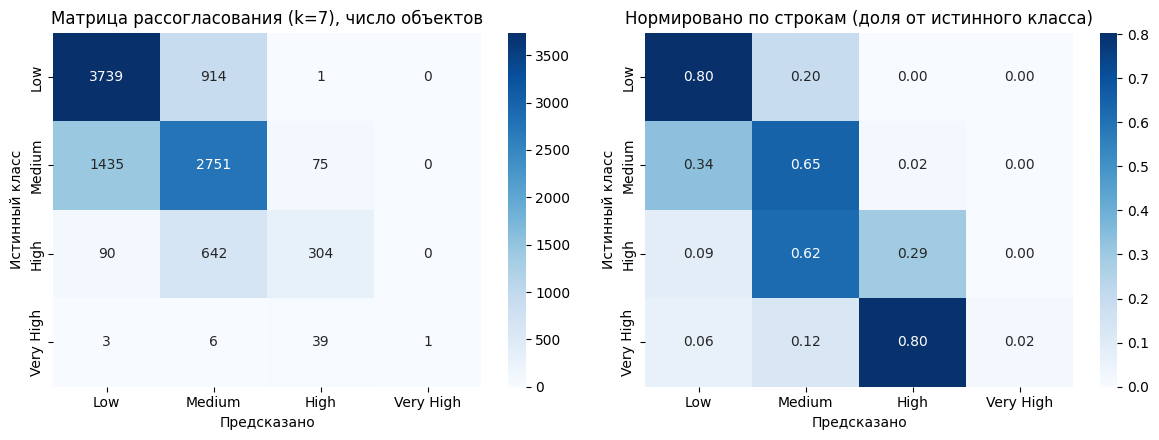

              precision    recall  f1-score   support

         Low       0.71      0.80      0.75      4654
      Medium       0.64      0.65      0.64      4261
        High       0.73      0.29      0.42      1036
   Very High       1.00      0.02      0.04        49

    accuracy                           0.68     10000
   macro avg       0.77      0.44      0.46     10000
weighted avg       0.68      0.68      0.67     10000



In [ ]:
knn = KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1).fit(Xs_train, ytr)
dummy = DummyClassifier(strategy='most_frequent').fit(Xs_train, ytr)

pred_te = knn.predict(Xs_test)
res = pd.DataFrame({
    'kNN':      {'train error': train_curve.loc[best_k, 'error'], 'test error': 1 - accuracy_score(yte, pred_te),
                 'test balanced acc': balanced_accuracy_score(yte, pred_te), 'test macro-F1': f1_score(yte, pred_te, average='macro')},
    'Baseline': {'train error': 1 - dummy.score(Xs_train, ytr), 'test error': 1 - dummy.score(Xs_test, yte),
                 'test balanced acc': balanced_accuracy_score(yte, dummy.predict(Xs_test)),
                 'test macro-F1': f1_score(yte, dummy.predict(Xs_test), average='macro')},
}).round(3)
display(res)

cm = confusion_matrix(yte, pred_te, labels=range(len(CLASSES)))
cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[0])
ax[0].set_title(f'Матрица рассогласования (k={best_k}), число объектов')
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[1])
ax[1].set_title('Нормировано по строкам (доля от истинного класса)')
for a in ax: a.set_xlabel('Предсказано'); a.set_ylabel('Истинный класс')
plt.tight_layout(); plt.show()

print(classification_report(yte, pred_te, target_names=CLASSES, zero_division=0))

k = 7. Если k большое, редкие классы не распознаются, если маленькое - переобучение и качество падает на тестовой выборке

10. Сделать выводы

In [ ]:
# Автоматический вердикт: лучше ли модели тривиального прогноза?
print(f"Регрессия:  R² на тесте = {reg_table.loc[('LinearRegression','test'),'R2']:.3f}  "
      f"(RMSE {reg_table.loc[('LinearRegression','test'),'RMSE']:.2f} против {reg_table.loc[('Baseline (среднее)','test'),'RMSE']:.2f} у baseline)")
print(f"Классификация: test error {res.loc['test error','kNN']:.3f} против {res.loc['test error','Baseline']:.3f} у baseline; "
      f"balanced accuracy {res.loc['test balanced acc','kNN']:.3f} против {res.loc['test balanced acc','Baseline']:.3f}")
if reg_table.loc[('LinearRegression','test'),'R2'] < 0.05 and res.loc['test balanced acc','kNN'] < res.loc['test balanced acc','Baseline'] + 0.05:
    print('-> Модели практически не лучше тривиальных: признаки почти не несут информации о популярности.')
else:
    print('-> Модели заметно лучше тривиальных: в признаках есть полезный сигнал.')

Регрессия:  R² на тесте = 0.720  (RMSE 8.51 против 16.08 у baseline)
Классификация: test error 0.320 против 0.535 у baseline; balanced accuracy 0.441 против 0.250
-> Модели заметно лучше тривиальных: в признаках есть полезный сигнал.


**Выводы**

1. **Регрессия** показывает достаточно хороший результат, предсказывая популярность с высокой детерминацией
2. **Классификация** заметно хуже регрессии, никогда не предсказывает непопулярный класс very high, но на нём предсказывает high довольно часто. Для High и medium предсказывает класс на 1 меньше